# 01 — Exploratory Data Analysis: Global Power Plant Database

Amaç: Veriyi tanımak, temizlik kararlarını vermek ve dashboard'daki 9 görsel için **içgörü adayları** bulmak.

Her bölümdeki **❓ sorulara** kısa notlarla cevap yaz — bunlar sonra README, rapor ve sunumda doğrudan işine yarayacak.

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px

pd.set_option("display.max_columns", 50)
df = pd.read_csv("../data/global_power_plant_database.csv", low_memory=False)
df.shape

(34936, 36)

## 1. Genel bakış
❓ Her satır neyi temsil ediyor? Hangi sütunlar sayısal, hangileri kategorik, hangileri ID/metin (analizde işe yaramaz)?

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 34936 entries, 0 to 34935
Data columns (total 36 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   country                         34936 non-null  str    
 1   country_long                    34936 non-null  str    
 2   name                            34936 non-null  str    
 3   gppd_idnr                       34936 non-null  str    
 4   capacity_mw                     34936 non-null  float64
 5   latitude                        34936 non-null  float64
 6   longitude                       34936 non-null  float64
 7   primary_fuel                    34936 non-null  str    
 8   other_fuel1                     1944 non-null   str    
 9   other_fuel2                     276 non-null    str    
 10  other_fuel3                     92 non-null     str    
 11  commissioning_year              17447 non-null  float64
 12  owner                           20868 non-n

In [4]:
df.head()

,country,country_long,name,gppd_idnr,capacity_mw,latitude,longitude,primary_fuel,other_fuel1,other_fuel2,other_fuel3,commissioning_year,owner,source,url,geolocation_source,wepp_id,year_of_capacity_data,generation_gwh_2013,generation_gwh_2014,generation_gwh_2015,generation_gwh_2016,generation_gwh_2017,generation_gwh_2018,generation_gwh_2019,generation_data_source,estimated_generation_gwh_2013,estimated_generation_gwh_2014,estimated_generation_gwh_2015,estimated_generation_gwh_2016,estimated_generation_gwh_2017,estimated_generation_note_2013,estimated_generation_note_2014,estimated_generation_note_2015,estimated_generation_note_2016,estimated_generation_note_2017
0,AFG,Afghanistan,Kajaki Hydroelectric Power Plant Afghanistan,GEODB0040538,33.0,32.322,65.1190,Hydro,NaN,NaN,NaN,NaN,NaN,GEODB,http://globalenergyobservatory.org,GEODB,1009793,2017.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,123.77,162.90,97.39,137.76,119.50,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1
1,AFG,Afghanistan,Kandahar DOG,WKS0070144,10.0,31.670,65.7950,Solar,NaN,NaN,NaN,NaN,NaN,Wiki-Solar,https://www.wiki-solar.org,Wiki-Solar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.43,17.48,18.25,17.70,18.29,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE
2,AFG,Afghanistan,Kandahar JOL,WKS0071196,10.0,31.623,65.7920,Solar,NaN,NaN,NaN,NaN,NaN,Wiki-Solar,https://www.wiki-solar.org,Wiki-Solar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.64,17.58,19.10,17.62,18.72,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE
3,AFG,Afghanistan,Mahipar Hydroelectric Power Plant Afghanistan,GEODB0040541,66.0,34.556,69.4787,Hydro,NaN,NaN,NaN,NaN,NaN,GEODB,http://globalenergyobservatory.org,GEODB,1009795,2017.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,225.06,203.55,146.90,230.18,174.91,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1
4,AFG,Afghanistan,Naghlu Dam Hydroelectric Power Plant Afghanistan,GEODB0040534,100.0,34.641,69.7170,Hydro,NaN,NaN,NaN,NaN,NaN,GEODB,http://globalenergyobservatory.org,GEODB,1009797,2017.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,406.16,357.22,270.99,395.38,350.80,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
capacity_mw,34936.0,163.355148,489.636072,1.0000,4.900000,16.745000,75.344250,22500.0000
latitude,34936.0,32.816637,22.638603,-77.8470,29.256475,39.727750,46.263125,71.2920
longitude,34936.0,-6.972803,78.405850,-179.9777,-77.641550,-2.127100,49.502675,179.3887
commissioning_year,17447.0,1997.414823,23.397835,1896.0000,1988.000000,2007.000000,2014.000000,2020.0000
year_of_capacity_data,14887.0,2018.218849,1.606428,2000.0000,2017.000000,2019.000000,2019.000000,2019.0000
generation_gwh_2013,6417.0,592.696107,2174.833482,-947.6000,1.947000,23.426000,199.706000,50834.0000
generation_gwh_2014,7226.0,656.863891,2231.464288,-989.6190,2.260000,23.608500,226.322250,32320.9170
generation_gwh_2015,8203.0,762.368840,2533.459828,-864.4280,2.664500,26.142000,285.862583,37433.6070
generation_gwh_2016,9144.0,693.149763,2404.516759,-768.6200,2.729000,22.462389,249.866750,32377.4770
generation_gwh_2017,9500.0,661.834161,2369.296957,-934.9440,2.467000,17.876500,214.505150,36448.6430


## 2. Eksik değerler
❓ Hangi sütunlar atılmalı, hangileri doldurulmalı, hangileri olduğu gibi bırakılmalı? Neden?

❓ Eksiklik rastgele mi? Örn. `commissioning_year` bazı ülkelerde/yakıt tiplerinde daha mı çok eksik? (Rastgele değilse zaman analizini yanıltır.)

In [6]:
(df.isna().mean() * 100).sort_values(ascending=False).round(1)

other_fuel3                       99.7
other_fuel2                       99.2
other_fuel1                       94.4
generation_gwh_2013               81.6
generation_gwh_2014               79.3
generation_gwh_2015               76.5
generation_gwh_2016               73.8
generation_gwh_2017               72.8
generation_gwh_2018               72.4
generation_gwh_2019               72.4
generation_data_source            67.4
year_of_capacity_data             57.4
estimated_generation_gwh_2013     53.9
wepp_id                           53.5
estimated_generation_gwh_2014     52.8
estimated_generation_gwh_2015     51.2
commissioning_year                50.1
estimated_generation_gwh_2016     49.7
owner                             40.3
estimated_generation_gwh_2017      5.1
geolocation_source                 1.2
url                                0.1
source                             0.0
country                            0.0
gppd_idnr                          0.0
name                     

In [2]:
# İpucu: eksiklik oranını gruplara göre karşılaştır
df.groupby("primary_fuel")["commissioning_year"].apply(lambda s: s.isna().mean()).sort_values()

primary_fuel
Petcoke           0.083333
Cogeneration      0.170732
Coal              0.185837
Storage           0.229630
Geothermal        0.243386
Oil               0.309052
Gas               0.313157
Other             0.348837
Waste             0.391386
Hydro             0.469396
Nuclear           0.497436
Wind              0.578219
Biomass           0.593007
Solar             0.671824
Wave and Tidal    1.000000
Name: commissioning_year, dtype: float64

## 3. Tek değişkenli dağılımlar
❓ `capacity_mw` dağılımı nasıl? Lineer eksende mi log eksende mi anlamlı?

❓ Yakıt tiplerinin **santral sayısı** ile **toplam kapasite** sıralaması aynı mı? (İpucu: güneş santrali çok ama küçük.)

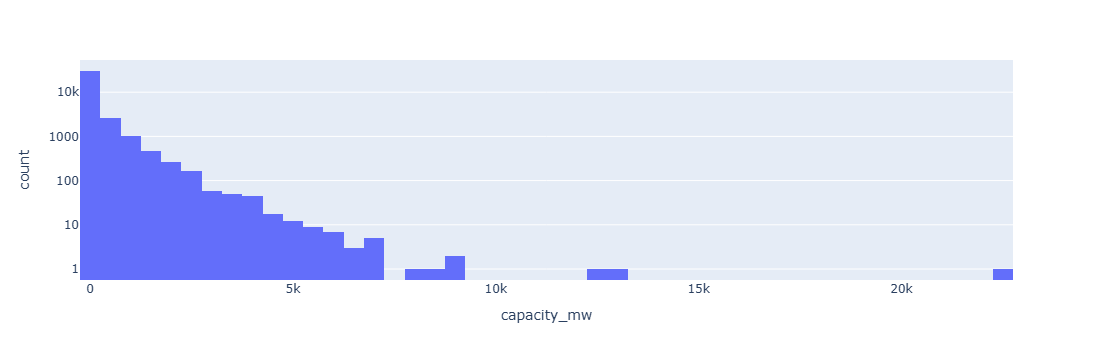

In [7]:
px.histogram(df, x="capacity_mw", nbins=100, log_y=True)

In [3]:
# Sayı vs kapasite karşılaştırması
df.groupby("primary_fuel")["capacity_mw"].agg(["count", "sum", "median"]).sort_values("sum", ascending=False)

,count,sum,median
primary_fuel,,,
Coal,2330,1.965541e+06,600.00000
Gas,3998,1.493051e+06,147.50000
Hydro,7156,1.053160e+06,20.00000
Nuclear,195,4.079118e+05,1888.00000
Wind,5344,2.630537e+05,27.00000
Oil,2320,2.618787e+05,9.00000
Solar,10665,1.883123e+05,5.80000
Biomass,1430,3.428130e+04,9.45000
Waste,1068,1.474871e+04,4.80000


## 4. Outlier analizi  ⚠️ (ödevde açıkça isteniyor)
❓ Hangi yöntemle tespit edeceksin? (IQR, z-score, log-ölçekte IQR, alan bilgisi…)

❓ Tespit edilen uç değerler **hata mı** yoksa **gerçek** mi (ör. Üç Boğaz Barajı ~22 GW gerçektir)? Gerçekse silme — işaretle.

❓ Fiziksel olarak imkânsız değerler var mı? Örn. üretim > kapasite × 8760 saat (capacity factor > 1), negatif üretim, gelecekteki yıl.

In [8]:
df.nlargest(10, "capacity_mw")[["name", "country_long", "primary_fuel", "capacity_mw"]]

,name,country_long,primary_fuel,capacity_mw
8453,Three Gorges Dam,China,Hydro,22500.0
5137,Baihetan Dam,China,Hydro,13050.0
8755,Xiluodu,China,Hydro,12600.0
19603,Surgutskaya GRES-2,Russia,Gas,8865.0
34668,Simon Bolivar (Guri),Venezuela,Hydro,8851.0
3272,Tucuruí,Brazil,Hydro,8535.0
16625,Kashiwazaki Kariwa,Japan,Nuclear,8212.0
2197,Itaipu (Parte Brasileira),Brazil,Hydro,7000.0
5703,East Hope Metals Wucaiwan power station,China,Coal,7000.0
18280,Itaipu Binacional Dam (Paraguay part),Paraguay,Hydro,7000.0


In [4]:
# İpucu: capacity factor = üretim (GWh) * 1000 / (kapasite (MW) * 8760)
cf = df["estimated_generation_gwh_2017"] * 1000 / (df["capacity_mw"] * 8760)
cf.describe()

count    33138.000000
mean         0.304818
std          0.162821
min          0.000000
25%          0.185910
50%          0.264840
75%          0.402563
max          2.251268
dtype: float64

## 5. Coğrafya
❓ Kapasitenin ne kadarı ilk 10 ülkede? Ülkelerin enerji karışımı (fosil/yenilenebilir) nasıl farklılaşıyor?

❓ Türkiye'nin profili dünya ortalamasından nasıl ayrılıyor?

In [5]:
df.groupby("country_long")["capacity_mw"].sum().nlargest(10)

country_long
China                       1.415067e+06
United States of America    1.204638e+06
India                       3.160885e+05
Russia                      2.282201e+05
Japan                       2.153658e+05
Brazil                      1.475893e+05
Canada                      1.435787e+05
Germany                     1.120404e+05
France                      1.106159e+05
South Korea                 9.947268e+04
Name: capacity_mw, dtype: float64

In [15]:
renew = ["Solar", "Wind", "Hydro", "Geothermal", "Biomass", "Wave and Tidal"]
cap = df.assign(is_renew=df["primary_fuel"].isin(renew))
by_country = cap.groupby("country_long").agg(
    total_mw=("capacity_mw", "sum"),
    renew_mw=("capacity_mw", lambda s: s[cap.loc[s.index, "is_renew"]].sum()),
)
by_country["renew_share"] = by_country["renew_mw"] / by_country["total_mw"]

# Very small countries can show 100% with 1-2 plants → filter by size
big = by_country[by_country["total_mw"] > 5000].sort_values("renew_share", ascending=False)
big.head(10), big.tail(10), by_country.loc["Turkey"]

(                  total_mw      renew_mw  renew_share
 country_long                                         
 Paraguay        8760.00000    8760.00000     1.000000
 Norway         32551.00000   31097.00000     0.955332
 Tajikistan      5296.40000    4686.40000     0.884827
 Brazil        147589.27133  122985.52113     0.833296
 New Zealand     6674.55000    5512.55000     0.825906
 Austria        11227.10000    9160.10000     0.815892
 Switzerland    13118.00000    9688.00000     0.738527
 Canada        143578.70000   97405.30000     0.678411
 Colombia       10924.00000    6790.00000     0.621567
 Portugal       14744.86400    8806.06400     0.597229,
                       total_mw  renew_mw  renew_share
 country_long                                         
 United Arab Emirates  30327.00     840.0     0.027698
 Belarus                8534.90     232.9     0.027288
 Bangladesh            11840.00     263.0     0.022213
 Hungary                6290.70      84.6     0.013448
 Saudi Ar

## 6. Zaman
❓ Yıllara göre devreye giren kapasite hangi yakıt tiplerinde artmış/azalmış? Yenilenebilire geçiş ne zaman hızlanmış?

❓ `commissioning_year` %50 eksik — bu bulguyu ne kadar zayıflatıyor?

In [6]:
yearly = df.dropna(subset=["commissioning_year"]).groupby(["commissioning_year", "primary_fuel"])["capacity_mw"].sum().reset_index()
px.area(yearly[yearly.commissioning_year >= 1950], x="commissioning_year", y="capacity_mw", color="primary_fuel")

In [17]:
us = df[df["country"] == "USA"].dropna(subset=["commissioning_year"])
yearly_us = us.groupby(["commissioning_year", "primary_fuel"])["capacity_mw"].sum().reset_index()
px.area(yearly_us[yearly_us.commissioning_year >= 1950],
        x="commissioning_year", y="capacity_mw", color="primary_fuel",
        title="USA — new capacity by commissioning year")

In [19]:
us = df[df["country"] != "USA"].dropna(subset=["commissioning_year"])
yearly_us = us.groupby(["commissioning_year", "primary_fuel"])["capacity_mw"].sum().reset_index()
px.area(yearly_us[yearly_us.commissioning_year >= 1950],
        x="commissioning_year", y="capacity_mw", color="primary_fuel",
        title="Other than USA — new capacity by commissioning year")

In [16]:
df.groupby("primary_fuel")["commissioning_year"].apply(lambda s: s.isna().mean()).sort_values()

primary_fuel
Petcoke           0.083333
Cogeneration      0.170732
Coal              0.185837
Storage           0.229630
Geothermal        0.243386
Oil               0.309052
Gas               0.313157
Other             0.348837
Waste             0.391386
Hydro             0.469396
Nuclear           0.497436
Wind              0.578219
Biomass           0.593007
Solar             0.671824
Wave and Tidal    1.000000
Name: commissioning_year, dtype: float64

## 7. İlişkiler (ML'e hazırlık)
❓ Kapasite ile üretim arasındaki ilişki yakıt tipine göre değişiyor mu? (Nükleer vs güneş capacity factor'ü)

❓ Ülkeleri hangi özelliklerle kümeleyebilirsin? (yakıt payları, ortalama santral büyüklüğü, toplam kapasite…)

❓ Regresyonda hedef ne olur, girdiler ne olur?

In [7]:
px.scatter(df, x="capacity_mw", y="estimated_generation_gwh_2017", color="primary_fuel", log_x=True, log_y=True, opacity=0.4)

In [9]:
df["cf_2017"] = df["generation_gwh_2017"] * 1000 / (df["capacity_mw"] * 8760)
cf = df[df["cf_2017"].between(0, 1)]   # actual generation only; drop impossible values
px.box(cf, x="primary_fuel", y="cf_2017", points=False,
       category_orders={"primary_fuel": cf.groupby("primary_fuel")["cf_2017"].median().sort_values(ascending=False).index.tolist()})

In [29]:
import sys, os
sys.path.append(os.path.abspath(".."))   # project root → makes "src" importable

from src.data_loader import load_clean
df = load_clean()
df.shape

(34936, 35)

In [31]:
from src.data_loader import load_clean   # notebook'ta: import sys; sys.path.append("..")
df = load_clean()
cap = df.pivot_table(index="country_long", columns="primary_fuel", values="capacity_mw", aggfunc="sum", fill_value=0)
totals = cap.sum(axis=1)
X = cap[totals > 5000].div(totals[totals > 5000], axis=0)   # shares, same 5 GW threshold as chart 2
X.shape, X.round(2).head()

((74, 15),
 primary_fuel  Biomass  Coal  Cogeneration   Gas  Geothermal  Hydro  Nuclear  \
 country_long                                                                  
 Algeria          0.00  0.00           0.0  0.96         0.0   0.00     0.00   
 Argentina        0.00  0.15           0.0  0.40         0.0   0.30     0.05   
 Australia        0.01  0.39           0.0  0.30         0.0   0.13     0.00   
 Austria          0.00  0.00           0.0  0.18         0.0   0.81     0.00   
 Azerbaijan       0.00  0.00           0.0  0.41         0.0   0.17     0.00   
 
 primary_fuel   Oil  Other  Petcoke  Solar  Storage  Waste  Wave and Tidal  \
 country_long                                                                
 Algeria       0.00   0.00      0.0   0.04      0.0    0.0             0.0   
 Argentina     0.04   0.04      0.0   0.02      0.0    0.0             0.0   
 Australia     0.02   0.00      0.0   0.06      0.0    0.0             0.0   
 Austria       0.00   0.00      0.0  

In [32]:
main = ["Coal", "Gas", "Oil", "Nuclear", "Hydro", "Wind", "Solar", "Biomass"]
Xm = X.reindex(columns=main, fill_value=0)
Xm["Other"] = 1 - Xm.sum(axis=1)     # everything else (geothermal, waste, storage …)
Xm.round(2).head()

primary_fuel,Coal,Gas,Oil,Nuclear,Hydro,Wind,Solar,Biomass,Other
country_long,,,,,,,,,
Algeria,0.00,0.96,0.00,0.00,0.00,0.00,0.04,0.00,0.00
Argentina,0.15,0.40,0.04,0.05,0.30,0.01,0.02,0.00,0.04
Australia,0.39,0.30,0.02,0.00,0.13,0.09,0.06,0.01,0.00
Austria,0.00,0.18,0.00,0.00,0.81,0.01,0.00,0.00,0.00
Azerbaijan,0.00,0.41,0.42,0.00,0.17,0.00,0.00,0.00,0.00


In [33]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import plotly.express as px

rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xm)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Xm, km.labels_)})
scores = pd.DataFrame(rows)
px.line(scores, x="k", y=["inertia", "silhouette"], markers=True, facet_row="variable").update_yaxes(matches=None)

In [34]:
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Xm)
profile = Xm.groupby(km.labels_).mean().round(2)
profile["n_countries"] = pd.Series(km.labels_).value_counts().sort_index().values
profile

primary_fuel,Coal,Gas,Oil,Nuclear,Hydro,Wind,Solar,Biomass,Other,n_countries
0,0.03,0.11,0.02,0.07,0.72,0.03,0.00,0.01,0.01,11
1,0.19,0.34,0.11,0.10,0.18,0.05,0.03,0.01,0.01,32
2,0.04,0.84,0.05,0.00,0.05,0.00,0.02,0.00,0.00,17
3,0.62,0.07,0.02,0.07,0.15,0.03,0.03,0.00,0.01,14


In [35]:
df[df.country_long=="Denmark"].groupby("primary_fuel").capacity_mw.sum()

primary_fuel
Biomass         88.0
Coal          5089.0
Gas            571.0
Geothermal      14.0
Oil            664.0
Solar          251.1
Wind          1408.1
Name: capacity_mw, dtype: float64